In [1]:
# import classy module
from classy import Class
# uncomment to get plots displayed in notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# create an instance of CLASS
model1 = Class()
model2 = Class()
model3 = Class()
model4 = Class()

In [2]:

beta1 = {
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':67.810,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'Neff':3.044,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'beta_ncdm':0.0,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl,dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'halofit',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '1.0, -4, 0.0, 0.0, 5.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}
model1.set(beta1)
model1.compute()


# Get background evolution
bg1 = model1.get_background()
print(bg1.keys())

# Extract needed quantities for model 1

z1 = bg1['z']
a1 = 1.0 / (1.0 + z1)
phi_scf1 = bg1['phi_scf']
dphi_scf1 = bg1['phi\'_scf']

V_scf1 = bg1['V_scf']
ddV_scf1 = bg1['V\'\'_scf']

rho_nu1 = bg1['(.)rho_ncdm[0]']
p_nu1 = bg1['(.)p_ncdm[0]']
rho_scf1 = bg1['(.)rho_scf']
p_scf1 = bg1['(.)p_scf']


H1 = bg1['H [1/Mpc]']


# You may also want to extract other density components
# Common keys in CLASS background:
rho_cdm1 = bg1['(.)rho_cdm']  # Cold dark matter
rho_b1 = bg1['(.)rho_b']      # Baryons
rho_g1 = bg1['(.)rho_g']      # Photons
rho_ur1 = bg1['(.)rho_ur']    # Ultra-relativistic species

# Calculate critical density
rho_crit1 = 3 * H1**2 / (8 * np.pi)  # in CLASS units


# Get beta from your parameters
beta1_val = 0.0



# Compute V_eff (equation 14)
V_eff1 = V_scf1/H1**2 + rho_nu1 - 3*p_nu1

# Compute w_eff (equation 19)
w_nu1 = p_nu1 / rho_nu1

w_phi1 =  p_scf1 / rho_scf1
w_eff1 = w_phi1 + ((beta1_val * dphi_scf1*rho_nu1)/(3 * H1*rho_scf1))




sources1, k_array1, tau_array1 = model1.get_sources()


# Get delta_ncdm for the first ncdm species at a specific k
k_target1 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array1 - k_target1))
  # Should be around 0.67-0.68

# Access phi+psi
phi_plus_psi1 = sources1['phi_plus_psi'][k_index]

# Convert tau to redshift
z_array1 = model1.z_of_tau(tau_array1)




CosmoComputationError: 

Error in Class: background_init(L:845) :condition (pba->shooting_failed == _TRUE_) is true; Shooting failed, try optimising input_get_guess(). Error message:

input_shooting(L:700) :error in fzero_Newton(input_try_unknown_parameters, x_inout, dxdF, unknown_parameters_size, ppr->tol_shooting_deltax, ppr->tol_shooting_deltaF, &fzw, &fevals, errmsg);
=>fzero_Newton(L:1118) :error in func(x_inout, x_size, param, F0, error_message);
=>input_try_unknown_parameters(L:1406) :error in background_init(&pr,&ba);
=>background_init(L:861) :error in background_solve(ppr,pba);
=>background_solve(L:1946) :error in background_initial_conditions(ppr,pba,pvecback,pvecback_integration,&(loga_ini));
=>background_initial_conditions(L:2363) :condition (fabs(pvecback[pba->index_bg_Omega_r]-1.) > ppr->tol_initial_Omega_r) is true; Omega_r = 0.000000e+00, not close enough to 1. Decrease a_ini_over_a_today_default in order to start from radiation domination.

In [ ]:

beta2 = {
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':67.810,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'N_ur':0.044,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'T_ncdm':0.71611,
        'deg_ncdm': 3,
        'beta_ncdm': 1.0,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl, dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'halofit',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '0.8, -3, 0.0, 0.0, 3.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}
model2.set(beta2)
model2.compute()


# Get background evolution
bg2 = model2.get_background()
print(bg2.keys())

# Extract needed quantities for model 2

z2 = bg2['z']
a2 = 1.0 / (1.0 + z2)
phi_scf2 = bg2['phi_scf']
V_scf2 = bg2['V_scf']  # or whatever the key is called
rho_nu2 = bg2['(.)rho_ncdm[0]']
p_nu2 = bg2['(.)p_ncdm[0]']
rho_scf2 = bg2['(.)rho_scf']
p_scf2 = bg2['(.)p_scf']
ddV_scf2= bg2['V\'\'_scf']


dphi_scf2 = bg2['phi\'_scf']

H2 = bg2['H [1/Mpc]']

# You may also want to extract other density components
# Common keys in CLASS background:
rho_cdm2 = bg2['(.)rho_cdm']  # Cold dark matter
rho_b2 = bg2['(.)rho_b']      # Baryons
rho_g2 = bg2['(.)rho_g']      # Photons
rho_ur2 = bg2['(.)rho_ur']    # Ultra-relativistic species

# Calculate critical density
rho_crit2 = 3 * H2**2 / (8 * np.pi)  # in CLASS units

# Get beta from your parameters
beta2_val = 1.0


# Compute V_eff (equation 14)
V_eff2 = V_scf2/H2**2 + rho_nu2 - 3*p_nu2

# Compute w_eff (equation 19)
w_nu2 = p_nu2 / rho_nu2
w_phi2 =  p_scf2 / rho_scf2
w_eff2 = w_phi2 + ((beta2_val * dphi_scf2*rho_nu2)/(3 * H2*rho_scf2))




sources2, k_array2, tau_array2 = model2.get_sources()


# Get delta_ncdm for the first ncdm species at a specific k
k_target2 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array2 - k_target2))
  # Should be around 0.67-0.68

# Access phi+psi
phi_plus_psi2 = sources2['phi_plus_psi'][k_index]

# Convert tau to redshift
z_array2 = model2.z_of_tau(tau_array2)


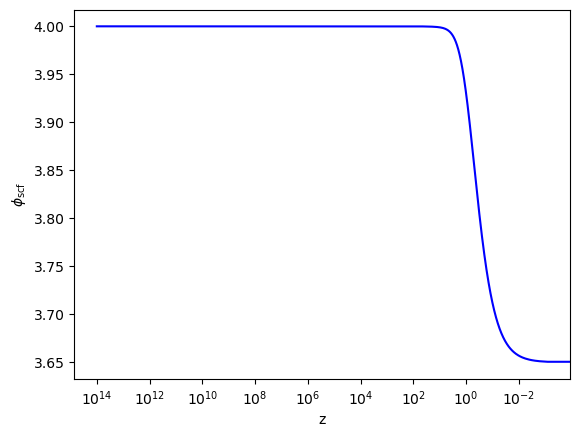

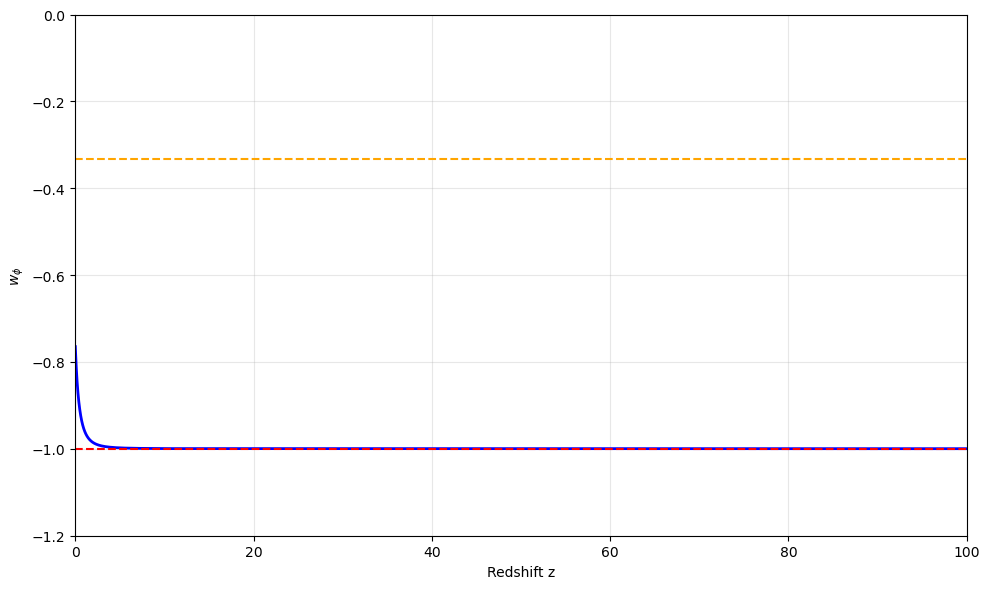

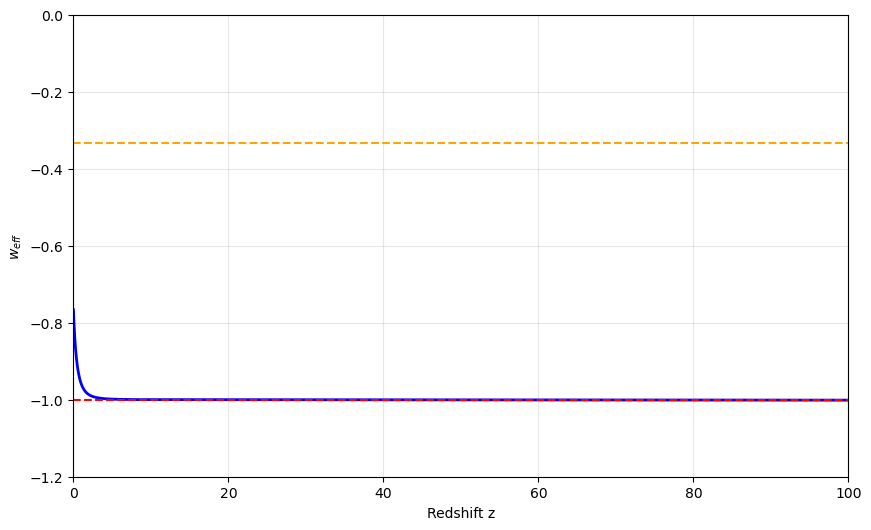

In [20]:
plt.plot(z2, phi_scf2, 'b-', label=r'$\beta=1, \ \alpha=2$')
plt.xscale('log')
plt.xlabel('z')
plt.ylabel(r'$\phi_{\rm scf}$')
plt.gca().invert_xaxis()
plt.show()
# Plot w_φ vs redshift
fig, ax = plt.subplots(figsize=(10, 6))
#ax.plot(z1, w_phi1, 'black', linewidth=2, label=r'$\beta=0, \alpha=2$')
ax.plot(z2, w_phi2, 'b-', linewidth=2, label=r'$\beta=1, \alpha=2$')
#ax.plot(z3, w_phi3, 'g-', linewidth=2, label=r'$\beta=-0.5, \alpha=2$')
#ax.plot(z4, w_phi4, 'r-', linewidth=2, label=r'$\beta=1, \alpha=3$')
ax.set_xlabel('Redshift z')
ax.set_ylabel(r'$w_\phi$')
#ax.set_xscale('log')
ax.set_xlim(0.0, 100)
ax.set_ylim(-1.2, 0.0)
ax.axhline(-1, color='red', linestyle='--', label='w = -1')
ax.axhline(-1/3, color='orange', linestyle='--', label='w = -1/3 ')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot w_φ vs redshift
fig, ax = plt.subplots(figsize=(10, 6))
#ax.plot(z1, w_eff1, 'black', linewidth=2, label=r'$\beta=0, f=2$')
ax.plot(z2, w_eff2, 'b-', linewidth=2, label=r'$\beta=1, f=2$')
#ax.plot(z3, w_eff3, 'g-', linewidth=2, label=r'$\beta=-0.5, f=2$')
#ax.plot(z4, w_eff4, 'r-', linewidth=2, label=r'$\beta=1, f=3$')
ax.set_xlabel('Redshift z')
ax.set_ylabel(r'$w_{eff}$')
#ax.set_xscale('log')
ax.set_xlim(0.0, 100)
ax.set_ylim(-1.2, 0.0)
ax.axhline(-1, color='red', linestyle='--', label='w = -1 (cosmological constant)')
ax.axhline(-1/3, color='orange', linestyle='--', label='w = -1/3 (acceleration threshold)')
#ax.legend()
ax.grid(True, alpha=0.3)
#plt.tight_layout()
#plt.savefig('w_eff_eos.pdf')
plt.show()


In [5]:
# beta=-0.79 e lambda = 1.22
####################################################
#
# Cosmological parameters and other CLASS parameters
#
####################################################
beta3 = {# LambdaCDM parameters (Planck 18 + lensing + BAO bestfit)
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':67.810,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'N_ur':0.044,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'T_ncdm':0.71611,
        'deg_ncdm': 3,
        'beta_ncdm': 0.8,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl, dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'halofit',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '1.5, -6, 0.0, 0.0, 3.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}
model3.set(beta3)
model3.compute()

# Get background evolution
bg3 = model3.get_background()
print(bg3.keys())


# Extract needed quantities for model 3

z3 = bg3['z']
a3 = 1.0 / (1.0 + z3)
phi_scf3 = bg3['phi_scf']
V_scf3 = bg3['V_scf']  # or whatever the key is called
rho_nu3 = bg3['(.)rho_ncdm[0]']
p_nu3 = bg3['(.)p_ncdm[0]']
rho_scf3 = bg3['(.)rho_scf']
p_scf3 = bg3['(.)p_scf']
dphi_scf3 = bg3['phi\'_scf']
H3 = bg3['H [1/Mpc]']
ddV_scf3= bg3['V\'\'_scf']

# You may also want to extract other density components
# Common keys in CLASS background:
rho_cdm3 = bg3['(.)rho_cdm']  # Cold dark matter
rho_b3 = bg3['(.)rho_b']      # Baryons
rho_g3 = bg3['(.)rho_g']      # Photons
rho_ur3 = bg3['(.)rho_ur']    # Ultra-relativistic species

# Calculate critical density
rho_crit3 = 3 * H3**2 / (8 * np.pi)  # in CLASS units

# Get beta from your parameters
beta3_val = 0.8


# Compute V_eff (equation 14)
V_eff3 = V_scf3/H3**2 + rho_nu3 - 3*p_nu3 
# Compute w_eff (equation 19)

w_nu3 = p_nu3 / rho_nu3
w_phi3 =  p_scf3 / rho_scf3


w_eff3 = w_phi3 + ((beta3_val * dphi_scf3*rho_nu3)/(3 * H3*rho_scf3))




sources3, k_array3, tau_array3 = model3.get_sources()


# Get delta_ncdm for the first ncdm species at a specific k
k_target3 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array3 - k_target3))
  # Should be around 0.67-0.68

# Access phi+psi
phi_plus_psi3 = sources3['phi_plus_psi'][k_index]

# Convert tau to redshift
z_array3 = model3.z_of_tau(tau_array3)

dict_keys(['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_ncdm[0]', '(.)p_ncdm[0]', '(.)rho_ur', '(.)rho_crit', '(.)rho_scf', '(.)p_scf', '(.)p_prime_scf', 'phi_scf', "phi'_scf", 'V_scf', "V'_scf", "V''_scf", '(.)rho_tot', '(.)p_tot', '(.)p_tot_prime', 'Omega_r(z)', 'Omega_m(z)', 'gr.fac. D', 'gr.fac. f'])


In [6]:
# beta=1 e lambda = 1.22
####################################################
#
# Cosmological parameters and other CLASS parameters
#
####################################################
beta4 = {# LambdaCDM parameters (Planck 18 + lensing + BAO bestfit)
        'omega_b':0.02238280,
        'omega_cdm':0.1201075,
        'H0':67.810,
        'A_s':2.100549e-09,
        'n_s':0.9660499,
        # other fixed parameters
        'N_ur':2.0328,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'beta_ncdm': 0.2,
        # settings for the output quantites
        'output':'mPk, tCl, pCl, lCl, dTk',
        'lensing':'yes',
        'P_k_max_h/Mpc':1.0,
        'non_linear':'halofit',
        'Omega_fld': 0.0,
        'Omega_scf': -1,
        'Omega_Lambda': 0.0,
        'scf_parameters': '1.5, -6, 0.0, 0.0, 3.0, 0.0',
        'attractor_ic_scf': 'no',
        'scf_tuning_index': 1,
        
}
model4.set(beta4)
model4.compute()

# Get background evolution
bg4 = model4.get_background()
print(bg4.keys())

# Extract needed quantities for model 4

z4 = bg4['z']
a4 = 1.0 / (1.0 + z4)
phi_scf4 = bg4['phi_scf']
V_scf4 = bg4['V_scf']  # or whatever the key is called
rho_nu4 = bg4['(.)rho_ncdm[0]']
p_nu4 = bg4['(.)p_ncdm[0]']
rho_scf4 = bg4['(.)rho_scf']
p_scf4 = bg4['(.)p_scf']
ddV_scf4= bg4['V\'\'_scf']

dphi_scf4 = bg4['phi\'_scf']
H4 = bg4['H [1/Mpc]']


# You may also want to extract other density components
# Common keys in CLASS background:
rho_cdm4 = bg4['(.)rho_cdm']  # Cold dark matter
rho_b4 = bg4['(.)rho_b']      # Baryons
rho_g4 = bg4['(.)rho_g']      # Photons
rho_ur4 = bg4['(.)rho_ur']    # Ultra-relativistic species

# Calculate critical density
rho_crit4 = 3 * H4**2 / (8 * np.pi)  # in CLASS units


# Get beta from your parameters
beta4_val = 0.2


# Compute V_eff (equation 14)
V_eff4 = V_scf4/H4**2 + rho_nu4 - 3*p_nu4 

# Compute w_eff (equation 19)


w_nu4 = p_nu4 / rho_nu4
w_phi4 =  p_scf4 / rho_scf4
w_eff4 = w_phi4 + ((beta4_val * dphi_scf4*rho_nu4)/(3* H4*rho_scf4))




sources4, k_array4, tau_array4 = model4.get_sources()


# Get delta_ncdm for the first ncdm species at a specific k
k_target4 = 1e-3 # Choose your k scale in Mpc^-1
k_index = np.argmin(np.abs(k_array4 - k_target4))
  # Should be around 0.67-0.68

# Access phi+psi
phi_plus_psi4 = sources4['phi_plus_psi'][k_index]

# Convert tau to redshift
z_array4 = model4.z_of_tau(tau_array4)



dict_keys(['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_ncdm[0]', '(.)p_ncdm[0]', '(.)rho_ur', '(.)rho_crit', '(.)rho_scf', '(.)p_scf', '(.)p_prime_scf', 'phi_scf', "phi'_scf", 'V_scf', "V'_scf", "V''_scf", '(.)rho_tot', '(.)p_tot', '(.)p_tot_prime', 'Omega_r(z)', 'Omega_m(z)', 'gr.fac. D', 'gr.fac. f'])


In [7]:
print("Ω_m1     =", model1.Omega0_m())
print("Ω_m2     =", model2.Omega0_m())
print("Ω_m3    =", model3.Omega0_m())
print("Ω_m4     =", model4.Omega0_m())

Ω_m1     = 0.31128388260007894
Ω_m2     = 0.35107063985592696
Ω_m3    = 0.33567857558022046
Ω_m4     = 0.3119430652521439


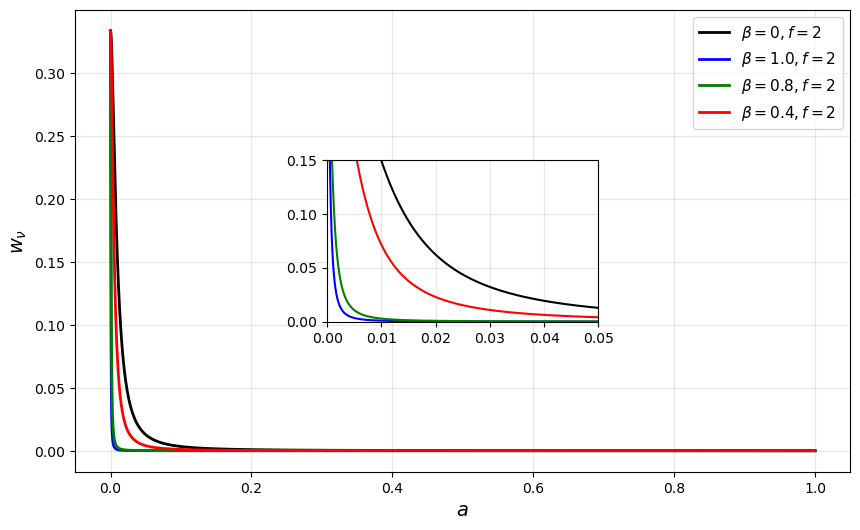

In [8]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Single figure with all models
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(a1, w_nu1, 'black', linewidth=2, label=r'$\beta=0, f=2$')
ax.plot(a2, w_nu2, 'b-', linewidth=2, label=r'$\beta=1.0, f=2$')
ax.plot(a3, w_nu3, 'g-', linewidth=2, label=r'$\beta=0.8, f=2$')
ax.plot(a4, w_nu4, 'r-', linewidth=2, label=r'$\beta=0.4, f=2$')
# Add inset
axins = inset_axes(ax, width="35%", height="35%", loc='center')
axins.plot(a1, w_nu1, 'black', linewidth=1.5)
axins.plot(a2, w_nu2, 'b-', linewidth=1.5)
axins.plot(a3, w_nu3, 'g-', linewidth=1.5)
axins.plot(a4, w_nu4, 'r-', linewidth=1.5)
axins.set_xlim(0.0, 0.05)  # Zoom on transition
axins.set_ylim(0, 0.15)
axins.grid(True, alpha=0.3)
ax.set_xlabel(r'$a$', fontsize=14)
ax.set_ylabel(r'$w_\nu$', fontsize=14)
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3)
plt.savefig('w_nu_all_models.pdf')
plt.show()

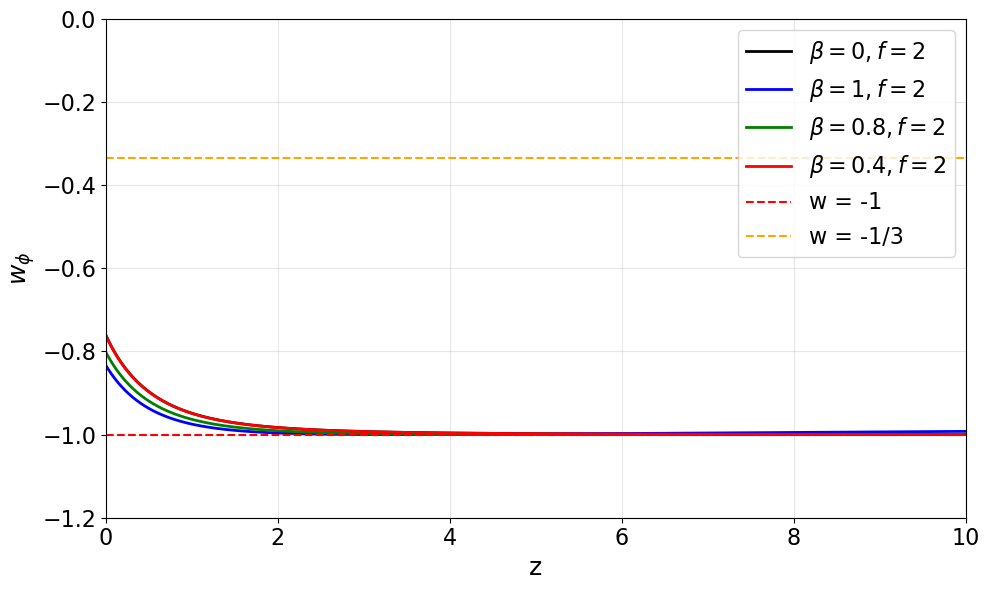

In [9]:
# Plot w_φ vs redshift
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(z1, w_phi1, 'black', linewidth=2, label=r'$\beta=0, f=2$')
ax.plot(z2, w_phi2, 'b-', linewidth=2, label=r'$\beta=1, f=2$')
ax.plot(z3, w_phi3, 'g-', linewidth=2, label=r'$\beta=0.8, f=2$')
ax.plot(z4, w_phi4, 'r-', linewidth=2, label=r'$\beta=0.4, f=2$')

ax.set_xlabel('z', fontsize=18)
ax.set_ylabel(r'$w_\phi$', fontsize=18)

ax.set_xlim(0.0, 10)
ax.set_ylim(-1.2, 0.0)

# Increase tick label size
ax.tick_params(axis='both', which='major', labelsize=16)

ax.axhline(-1, color='red', linestyle='--', label='w = -1')
ax.axhline(-1/3, color='orange', linestyle='--', label='w = -1/3')

ax.legend(fontsize=16)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('w_phi_eos.pdf')
plt.show()


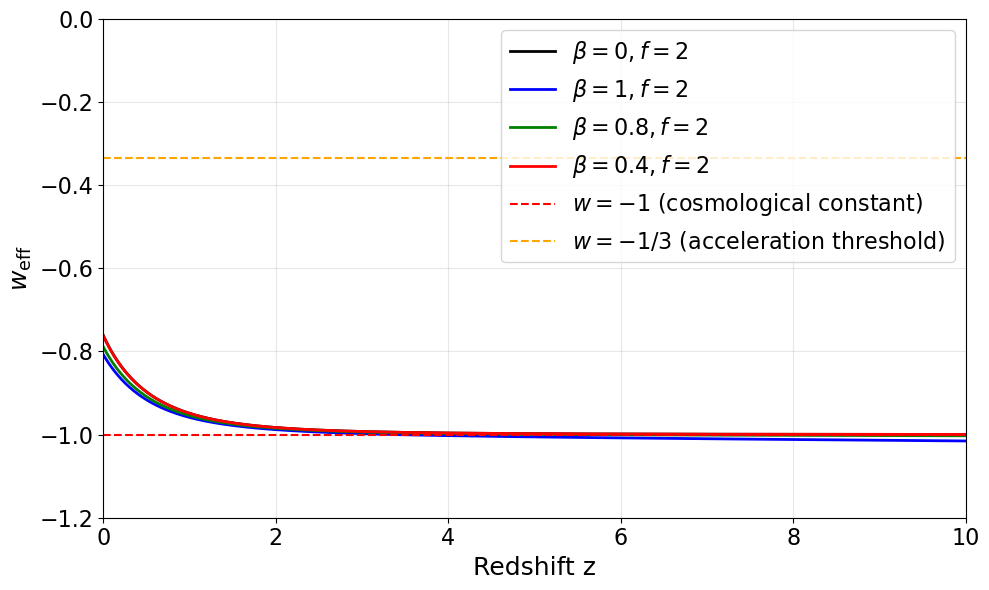

In [10]:
# Plot w_eff vs redshift
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(z1, w_eff1, 'black', linewidth=2, label=r'$\beta=0, f=2$')
ax.plot(z2, w_eff2, 'b-', linewidth=2, label=r'$\beta=1, f=2$')
ax.plot(z3, w_eff3, 'g-', linewidth=2, label=r'$\beta=0.8, f=2$')
ax.plot(z4, w_eff4, 'r-', linewidth=2, label=r'$\beta=0.4, f=2$')

ax.set_xlabel('Redshift z', fontsize=18)
ax.set_ylabel(r'$w_{\rm eff}$', fontsize=18)

# Increase tick label size
ax.tick_params(axis='both', which='major', labelsize=16)

ax.set_xlim(0.0, 10)
ax.set_ylim(-1.2, 0.0)

ax.axhline(-1, color='red', linestyle='--', linewidth=1.5,
           label=r'$w = -1$ (cosmological constant)')
ax.axhline(-1/3, color='orange', linestyle='--', linewidth=1.5,
           label=r'$w = -1/3$ (acceleration threshold)')

ax.legend(fontsize=16)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('w_eff_eos.pdf', bbox_inches='tight')
plt.show()


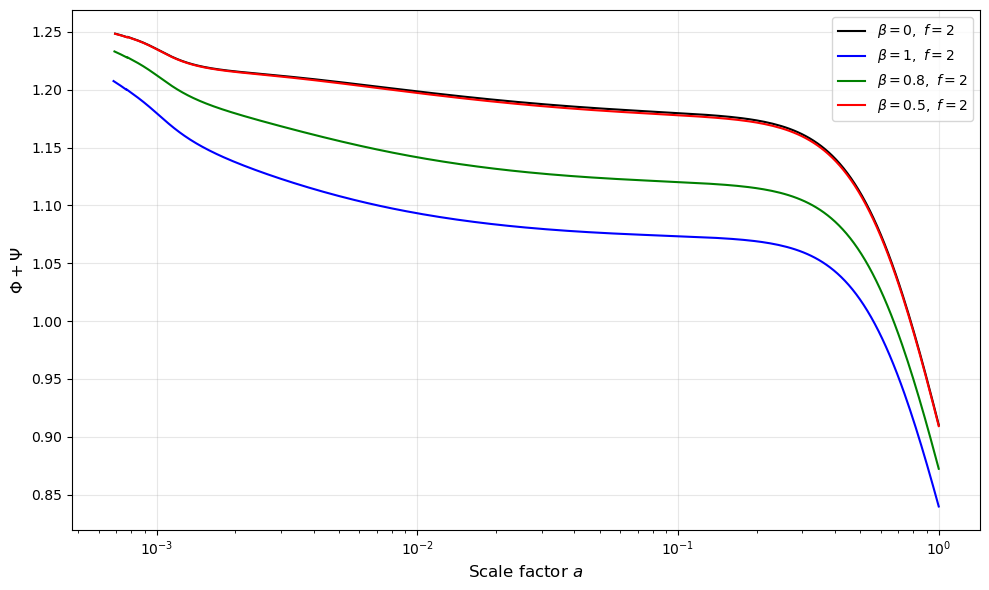

In [11]:
# Convert tau to scale factor
a_array1 = 1.0 / (1.0 + z_array1)
a_array2 = 1.0 / (1.0 + z_array2)
a_array3 = 1.0 / (1.0 + z_array3)
a_array4 = 1.0 / (1.0 + z_array4)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(a_array1, phi_plus_psi1, 'black', label=r'$\beta=0, \ f=2$')
plt.plot(a_array2, phi_plus_psi2, 'b-', label=r'$\beta=1, \ f=2$')
plt.plot(a_array3, phi_plus_psi3, 'g-', label=r'$\beta=0.8, \ f=2$')
plt.plot(a_array4, phi_plus_psi4, 'r-', label=r'$\beta=0.5, \ f=2$')

plt.xlabel('Scale factor $a$', fontsize=12)
plt.ylabel(r'$\Phi + \Psi$', fontsize=12)  # Specify which k
plt.xscale('log')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()  # Prevents label cutoff
plt.savefig('phi_plus_psi_beta.pdf', dpi=300, bbox_inches='tight')  # Higher quality
plt.show()



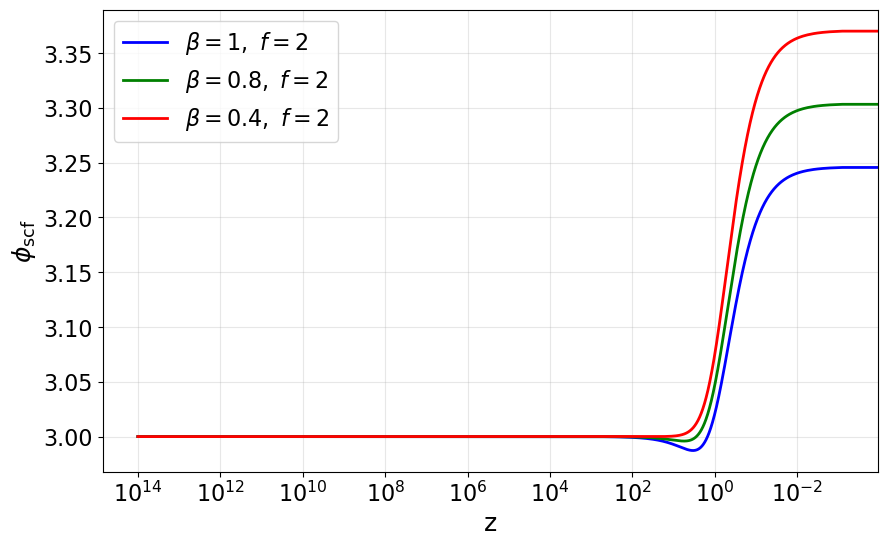

In [12]:
plt.figure(figsize=(10, 6))

#plt.plot(z1, phi_scf1, 'black', linewidth=2, label=r'$\beta=0, \ f=2$')
plt.plot(z2, phi_scf2, 'b-', linewidth=2, label=r'$\beta=1, \ f=2$')
plt.plot(z3, phi_scf3, 'g-', linewidth=2, label=r'$\beta=0.8, \ f=2$')
plt.plot(z4, phi_scf4, 'r-', linewidth=2, label=r'$\beta=0.4, \ f=2$')

plt.xscale('log')

plt.xlabel('z', fontsize=18)
plt.ylabel(r'$\phi_{\rm scf}$', fontsize=18)

# Increase tick label size
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.gca().invert_xaxis()

plt.legend(fontsize=16)

plt.grid(True, alpha=0.3)

plt.savefig('phi_z_beta.pdf', bbox_inches='tight')
plt.show()


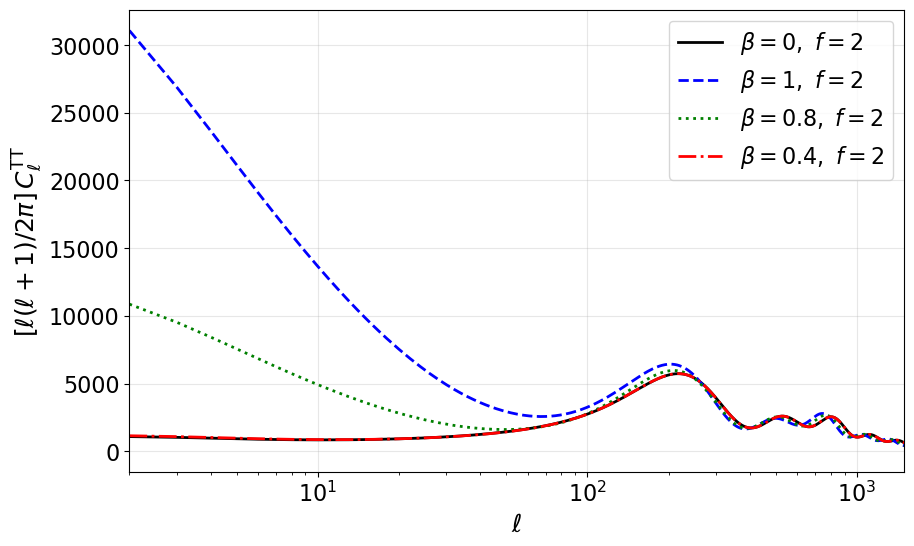

In [13]:
# get lesned C_l spectra
cls1 = model1.lensed_cl(2500)
cls2 = model2.lensed_cl(2500)
cls3 = model3.lensed_cl(2500)
cls4 = model4.lensed_cl(2500)

# Model 1: β=0

model1.set({'temperature contributions': 'lisw'})
model1.compute()
cl_eisw1 = model1.raw_cl(2500)

# Model 2: β=1

model2.set({'temperature contributions': 'lisw'})
model2.compute()
cl_eisw2 = model2.raw_cl(2500)

# Model 3: β=-0.7

model3.set({'temperature contributions': 'lisw'})
model3.compute()
cl_eisw3 = model3.raw_cl(2500)

# get multipoles l
ll1 = cls1['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT1 = cls1['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE1 = cls1['ee'][2:]


ll2 = cls2['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT2 = cls2['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE2 = cls2['ee'][2:]

ll3 = cls3['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT3 = cls3['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE3 = cls3['ee'][2:]

ll4 = cls4['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT4 = cls4['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE4 = cls4['ee'][2:]

# plot C_l^TT
T_CMB = 2.7255e6
plt.figure(figsize=(10, 6))

plt.xscale('log')
plt.yscale('linear')
plt.xlim(2, 1500)

plt.xlabel(r'$\ell$', fontsize=18)
plt.ylabel(r'$[\ell(\ell+1)/2\pi]\, C_\ell^{\mathrm{TT}}$', fontsize=18)

# Increase tick size
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Plot lines with consistent linewidth
plt.plot(ll1, (clTT1*ll1*(ll1+1))/(2.*np.pi)*T_CMB**2,
         color='black', linestyle='-', linewidth=2, label=r'$\beta=0, \ f=2$')

plt.plot(ll2, (clTT2*ll2*(ll2+1))/(2.*np.pi)*T_CMB**2,
         color='b', linestyle='--', linewidth=2, label=r'$\beta=1, \ f=2$')

plt.plot(ll3, (clTT3*ll3*(ll3+1))/(2.*np.pi)*T_CMB**2,
         color='g', linestyle=':', linewidth=2, label=r'$\beta=0.8, \ f=2$')

plt.plot(ll4, (clTT4*ll4*(ll4+1))/(2.*np.pi)*T_CMB**2,
         color='r', linestyle='-.', linewidth=2, label=r'$\beta=0.4, \ f=2$')

plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)

plt.savefig('mnu3_cltt_beta.pdf', bbox_inches='tight')
plt.show()


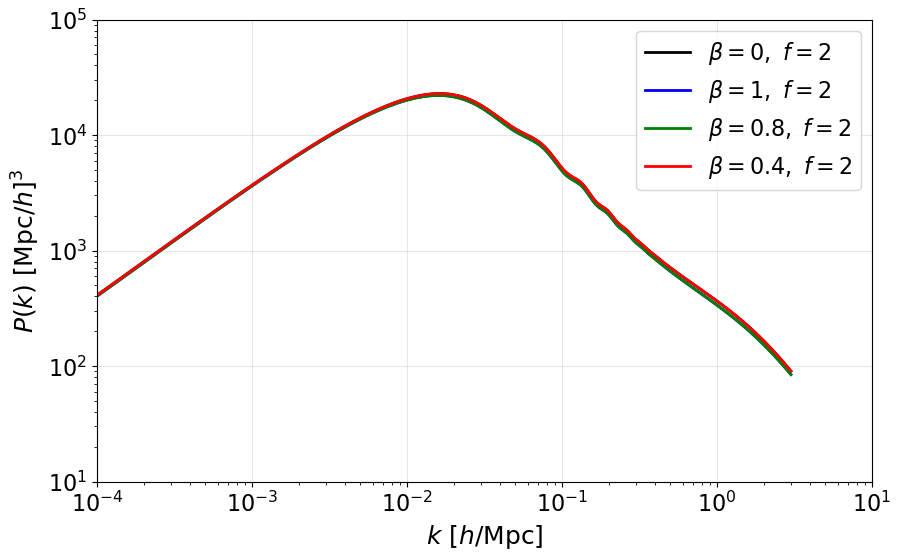

In [28]:
# get P(k) at redhsift z=0
import numpy as np
kk = np.geomspace(1e-4,3.0,num=1000) # k in h/Mpc
h1 = model1.h() # get reduced Hubble for conversions to h/Mpc
h2 = model2.h() # get reduced Hubble for conversions to h/Mpc
h3 = model3.h() # get reduced Hubble for conversions to h/Mpc

h4 = model4.h() # get reduced Hubble for conversions to h/Mpc

# Note that kk*h is the array of k in 1/Mpc
Pk1 = model1.get_pk_all(kk*h1,0.)*h1**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units
Pk2 = model2.get_pk_all(kk*h2,0.)*h2**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units
Pk3 = model3.get_pk_all(kk*h3,0.)*h3**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units
Pk4 = model4.get_pk_all(kk*h4,0.)*h4**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units


# By default, this is the non-linear matter power spectrum; to get the linear one,
# pass the optional argument 'nonlinear=False' to .get_pk_all()

# plot P(k)
plt.figure(figsize=(10, 6))

plt.xscale('log')
plt.yscale('log')
plt.xlim(1e-4, 1e1)
plt.ylim(1e1, 1e5)

plt.xlabel(r'$k \,\, [h/\mathrm{Mpc}]$', fontsize=18)
plt.ylabel(r'$P(k) \,\, [\mathrm{Mpc}/h]^3$', fontsize=18)

# Increase tick label sizes
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Plot with consistent line width
plt.plot(kk, Pk1, 'black', linewidth=2, label=r'$\beta=0, \ f=2$')
plt.plot(kk, Pk2, 'b-', linewidth=2, label=r'$\beta=1, \ f=2$')
plt.plot(kk, Pk3, 'g-', linewidth=2, label=r'$\beta=0.8, \ f=2$')
plt.plot(kk, Pk4, 'r-', linewidth=2, label=r'$\beta=0.4, \ f=2$')

plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)

plt.savefig('mnu3_pk_beta.pdf', bbox_inches='tight')
plt.show()


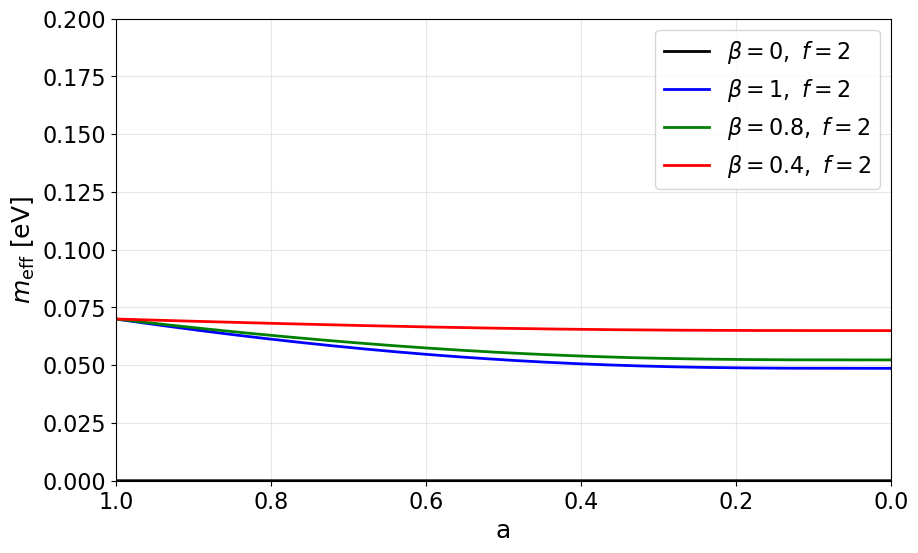

In [29]:
import numpy as np
import matplotlib.pyplot as plt

beta_ncdm1 = 0
beta_ncdm2 = 1.0
beta_ncdm3 = 0.8
beta_ncdm4 = 0.2


# phi0 is the CURRENT value (at z=0, which is the LAST element)
phi0_1 = phi_scf1[-1]  # This is correct
phi0_2 = phi_scf2[-1]
phi0_3 = phi_scf3[-1]
phi0_4 = phi_scf4[-1]

# Effective mass evolution
# m_eff(z) = m_ν,0 * exp(β * (φ(z) - φ_0))
m_eff1 = 0. * np.exp(beta_ncdm1 * (phi_scf1 - phi0_1))
m_eff2 = 0.07 * np.exp(beta_ncdm2 * (phi_scf2 - phi0_2))
m_eff3 = 0.07 * np.exp(beta_ncdm3 * (phi_scf3 - phi0_3))
m_eff4 = 0.07 * np.exp(beta_ncdm4 * (phi_scf4 - phi0_4))

# Plot
plt.figure(figsize=(10, 6))

plt.plot(a1, m_eff1, 'black', linewidth=2, label=r'$\beta=0, \ f=2$')
plt.plot(a2, m_eff2, 'b-', linewidth=2, label=r'$\beta=1, \ f=2$')
plt.plot(a3, m_eff3, 'g-', linewidth=2, label=r'$\beta=0.8, \ f=2$')
plt.plot(a4, m_eff4, 'r-', linewidth=2, label=r'$\beta=0.4, \ f=2$')

plt.xlabel('a', fontsize=18)
plt.ylabel(r'$m_{\rm eff}$ [eV]', fontsize=18)

# Increase tick sizes
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Inverted x-axis limits as in your code
plt.xlim(1, 0)
plt.ylim(0, 0.20)

plt.grid(True, alpha=0.3)
plt.legend(fontsize=16)

plt.savefig('m_eff_vs_z.pdf', bbox_inches='tight')
plt.show()



In [ ]:
# Compute m_eff^2 (general formula, valid for all regimes)
# m_eff^2 = d²V/dφ² + β² (ρ_ν - 3p_ν)
m_eff_squared2 = ddV_scf2 + beta2_val**2 * (rho_nu2 - 3*p_nu2)

# Compute m_eff
m_eff2 = np.sqrt(np.abs(m_eff_squared2)) * np.sign(m_eff_squared2)

# Compute the ratio
m_eff_over_H2 = m_eff2 / H2

# For stability, we need m_eff/H ≲ 1
print(f"Range of m_eff/H: [{np.min(m_eff_over_H2):.4f}, {np.max(m_eff_over_H2):.4f}]")
print(f"m_eff/H at z=0: {m_eff_over_H2[0]:.4f}")

# Check if the stability condition is satisfied
unstable_indices = np.where(m_eff_over_H2 > 1.0)[0]
if len(unstable_indices) > 0:
    print(f"WARNING: {len(unstable_indices)} redshift points have m_eff/H > 1 (potentially unstable)")
    print(f"First unstable redshift: z = {z2[unstable_indices[0]]:.4f}")
else:
    print("Model appears stable: m_eff/H ≲ 1 throughout evolution")

# Plot
plt.figure(figsize=(10, 6))
plt.plot(a2, m_eff_over_H2, 'b-', label=r'$pNGB$')

plt.xlabel('a', fontsize=18)
plt.ylabel(r'$m_{\rm eff,\phi}/H$', fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.yscale('log')
plt.xscale('log')
plt.xlim(1e-6, 1e0) 
plt.ylim(1e-5, 1e1)

plt.axhline(y=1.0, color='r', linestyle='--', alpha=0.5, label='Stability threshold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=16)

plt.savefig('mphi_H.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# Alternative: Plot absolute densities instead of Omega
fig1, ax1 = plt.subplots(figsize=(10, 7))

# Use regular plot instead of loglog
ax1.plot(a1, rho_g1, label='Photons', linewidth=2)
ax1.plot(a1, rho_ur1, label='Neutrinos (massless)', linewidth=2)
ax1.plot(a1, rho_nu1, label='Neutrinos (massive)', linewidth=2)
ax1.plot(a1, rho_b1, label='Baryons', linewidth=2)
ax1.plot(a1, rho_cdm1, label='CDM', linewidth=2)
ax1.plot(a1, rho_scf1, label='Scalar Field', linewidth=2)

# Set log scales manually
ax1.set_xscale('log')
ax1.set_yscale('log')

ax1.set_xlabel(r'$a$', fontsize=14)
ax1.set_ylabel(r'$\rho$', fontsize=14)
ax1.set_title(r'$\beta = 0$ and $f = 2$', fontsize=16)
ax1.legend(fontsize=11, loc='best')
ax1.grid(True, alpha=0.3, which='both')
ax1.set_xlim(a1.min(), a1.max())
plt.savefig('rho_1.pdf', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

# Alternative: Plot absolute densities instead of Omega
fig2, ax2 = plt.subplots(figsize=(10, 7))

# Use regular plot instead of loglog
ax2.plot(a2, rho_g2, label='Photons', linewidth=2)
ax2.plot(a2, rho_ur2, label='Neutrinos (massless)', linewidth=2)
ax2.plot(a2, rho_nu2, label='Neutrinos (massive)', linewidth=2)
ax2.plot(a2, rho_b2, label='Baryons', linewidth=2)
ax2.plot(a2, rho_cdm2, label='CDM', linewidth=2)
ax2.plot(a2, rho_scf2, label='Scalar Field', linewidth=2)

# Set log scales manually
ax2.set_xscale('log')
ax2.set_yscale('log')

ax2.set_xlabel(r'$a$', fontsize=14)
ax2.set_ylabel(r'$\rho$', fontsize=14)
ax2.set_title(r'$\beta = 1$ and $f = 2$', fontsize=16)
ax2.legend(fontsize=11, loc='best')
ax2.grid(True, alpha=0.3, which='both')
ax2.set_xlim(a2.min(), a2.max())
plt.savefig('rho_2.pdf', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

# Alternative: Plot absolute densities instead of Omega
fig3, ax3 = plt.subplots(figsize=(10, 7))

# Use regular plot instead of loglog
ax3.plot(a3, rho_g3, label='Photons', linewidth=2)
ax3.plot(a3, rho_ur3, label='Neutrinos (massless)', linewidth=2)
ax3.plot(a3, rho_nu3, label='Neutrinos (massive)', linewidth=2)
ax3.plot(a3, rho_b3, label='Baryons', linewidth=2)
ax3.plot(a3, rho_cdm3, label='CDM', linewidth=2)
ax3.plot(a3, rho_scf3, label='Scalar Field', linewidth=2)

# Set log scales manually
ax3.set_xscale('log')
ax3.set_yscale('log')

ax3.set_xlabel(r'$a$', fontsize=14)
ax3.set_ylabel(r'$\rho$', fontsize=14)
ax3.set_title(r'$\beta = -0.5$ and $f = 2$', fontsize=16)
ax3.legend(fontsize=11, loc='best')
ax3.grid(True, alpha=0.3, which='both')
ax3.set_xlim(a3.min(), a3.max())
plt.savefig('rho_3.pdf', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()


# Alternative: Plot absolute densities instead of Omega
fig4, ax4 = plt.subplots(figsize=(10, 7))

# Use regular plot instead of loglog
ax4.plot(a4, rho_g4, label='Photons', linewidth=2)
ax4.plot(a4, rho_ur4, label='Neutrinos (massless)', linewidth=2)
ax4.plot(a4, rho_nu4, label='Neutrinos (massive)', linewidth=2)
ax4.plot(a4, rho_b4, label='Baryons', linewidth=2)
ax4.plot(a4, rho_cdm4, label='CDM', linewidth=2)
ax4.plot(a4, rho_scf4, label='Scalar Field', linewidth=2)

# Set log scales manually
ax4.set_xscale('log')
ax4.set_yscale('log')

ax4.set_xlabel(r'$a$', fontsize=14)
ax4.set_ylabel(r'$\rho$', fontsize=14)
ax4.set_title(r'$\beta = 1$ and $f = 3$', fontsize=16)
ax4.legend(fontsize=11, loc='best')
ax4.grid(True, alpha=0.3, which='both')
ax4.set_xlim(a4.min(), a4.max())
plt.savefig('rho_4.pdf', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [ ]:
# Plot beta * phi to see coupling strength evolution
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(a1, 0 * phi_scf1, 'black', linewidth=2, label=r'$\beta=0, f=2$')
ax.plot(a2, 1.0 * phi_scf2, 'b-', linewidth=2, label=r'$\beta=1, f=2$')
ax.plot(a3, -0.5 * phi_scf3, 'g-', linewidth=2, label=r'$\beta=-0.5, f=2$')
ax.plot(a4, 1.0 * phi_scf4, 'r-', linewidth=2, label=r'$\beta=1, f=3$')

ax.set_xlabel(r'$a$', fontsize=14)
ax.set_ylabel(r'$\beta \phi$', fontsize=14)
ax.set_title(r'Coupling Strength Evolution', fontsize=14)
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('coupling_strength.pdf')
plt.show()

In [ ]:


# Plot V_eff
plt.figure(figsize=(10, 6))
plt.plot(z1+1, V_eff1, 'black', label=r'$\beta=0,  f=2$')
plt.plot(z2+1, V_eff2, 'b-', label=r'$\beta=1, \ f=2$')
plt.plot(z3+1, V_eff3, 'g-', label=r'$\beta=-0.5, \ f=2$')
plt.plot(z4+1, V_eff4, 'r-', label=r'$\beta=1, \ f=3$')

plt.xlabel('z+1', fontsize=12)
plt.ylabel(r'$V_{\rm eff}$', fontsize=12)
plt.xscale('log')
plt.xlim(1e0,1e8)
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('V_eff.pdf', dpi=300, bbox_inches='tight')
plt.show()
